# Sigmoid function basics

$$ \sigma(x) = \frac{1}{1+e^{-x}}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def sigmoid(x):
    sig = 1/(1+np.exp(-x))
    return sig

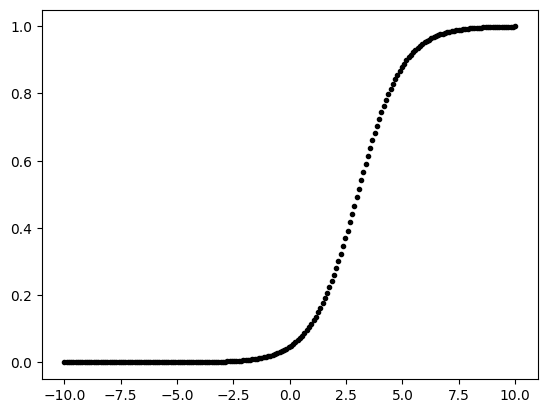

In [3]:
x = np.linspace(-10, 10, 200)
y = sigmoid(x-3)
plt.plot(x,y,'.k')
plt.show()

# Exploring the Iris dataset

In [4]:
df = pd.read_csv('iris_basic.csv')
df[50:70]

,sl,sw,pl,pw,target,tNames
50,7.0,3.2,4.7,1.4,1,versicolor
51,6.4,3.2,4.5,1.5,1,versicolor
52,6.9,3.1,4.9,1.5,1,versicolor
53,5.5,2.3,4.0,1.3,1,versicolor
54,6.5,2.8,4.6,1.5,1,versicolor
55,5.7,2.8,4.5,1.3,1,versicolor
56,6.3,3.3,4.7,1.6,1,versicolor
57,4.9,2.4,3.3,1.0,1,versicolor
58,6.6,2.9,4.6,1.3,1,versicolor
59,5.2,2.7,3.9,1.4,1,versicolor


<class 'numpy.ndarray'>
(150, 1)


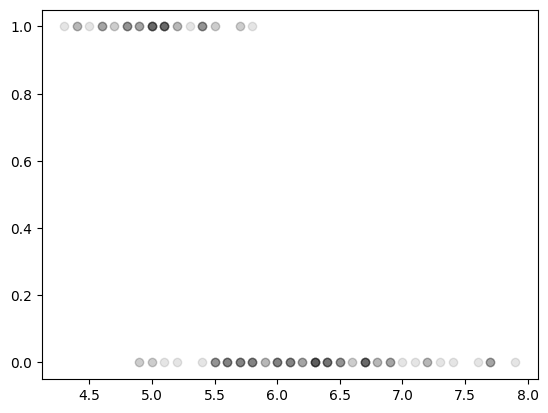

In [5]:
x1 = df['sl']
y = df['target'].to_numpy().reshape(-1,1)
#y = np.array(df['target'], ndmin=2).reshape(-1,1)
y = (y==0).astype(float) #casting
print(type(y))
print(y.shape)
plt.plot(x1, y,'ok', alpha=0.1)
plt.show()

# One parameter binary classifier
$J(\theta)$ or objective function or Log-Loss function

$$-\frac{1}{m}\sum[y\cdot log(p)+(1-y)\cdot log(1-p)]$$

In [6]:
# J Log Loss
def LogLoss(y,p):
    loss = -np.mean(y*np.log(p)+(1-y)*np.log(1-p))
    return loss

In [7]:
# BGD and its hyperparameters:
eta = 0.1
epoch = 500000 # bgd repetitions or n
X = np.column_stack([np.ones_like(x1), x1])
m = X.shape[0]
np.random.seed(100)
thetaH = np.random.rand(2,1)*10
thetaH

array([[5.43404942],
       [2.78369385]])

In [8]:
# BGD implementation
J = np.zeros((epoch,1))
for i in range(epoch):
    z = X@thetaH
    # z = np.dot(X,thetaH)
    p = sigmoid(z) # yH
    J[i] = LogLoss(y,p)
    nabla = (X.T@(p-y))/m
    thetaH = thetaH-eta*nabla
    #thetaH -=eta*nabla
thetaH

array([[27.82851211],
       [-5.17569641]])

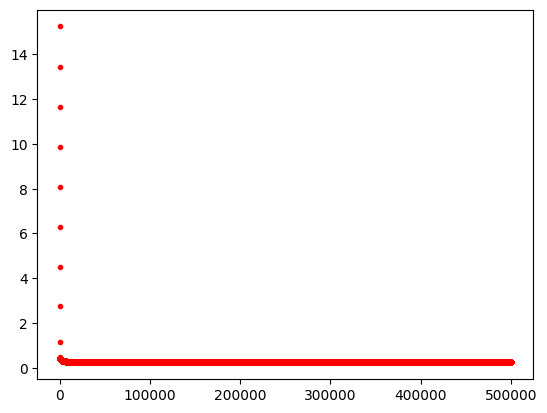

In [9]:
plt.plot(J,'.r')
plt.show()

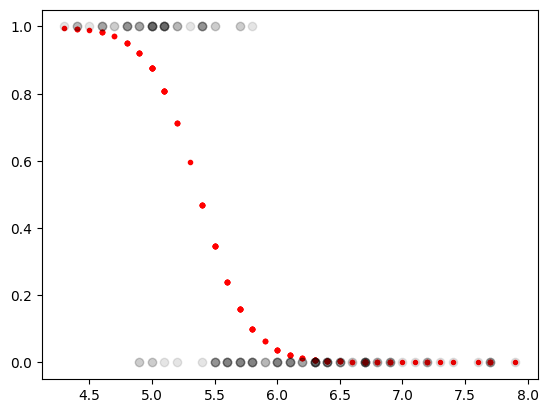

In [10]:
yM = sigmoid(X@thetaH)
plt.plot(x1, yM, '.r')
plt.plot(x1, y, 'ok', alpha=0.1)
plt.show()

<class 'numpy.ndarray'>
(150, 1)


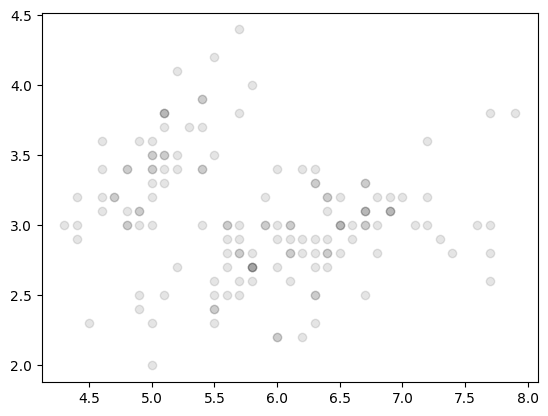

In [11]:
#Challenge
x1 = df['sl']
x2 = df['sw']
y = df['target'].to_numpy().reshape(-1,1)
#y = np.array(df['target'], ndmin=2).reshape(-1,1)
y = (y==2).astype(float) #casting
print(type(y))
print(y.shape)
plt.plot(x1, x2,'ok', alpha=0.1)
plt.show()

# Two-Parameters binary classifiers

In [12]:
x1 = df['sl'].to_numpy()
x2 = df['sw'].to_numpy()
y = df['target'].to_numpy()

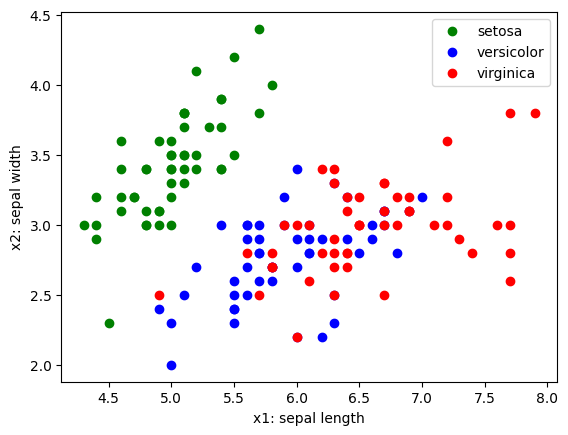

In [18]:
plt.plot(x1[y==0],x2[y==0],'og', label='setosa')
plt.plot(x1[y==1],x2[y==1],'ob', label='versicolor')
plt.plot(x1[y==2],x2[y==2],'or', label='virginica')
plt.xlabel('x1: sepal length')
plt.ylabel('x2: sepal width')
plt.legend()
plt.show()

In [22]:
X = np.column_stack([np.ones_like(x1), x1, x2])
Y = df['target'].to_numpy().reshape(-1,1)
Yt = (Y==0).astype(float) # For Classifying Setosa

In [27]:
# Hyperparameters
eta = 0.1
m = len(x1)
epoch = 1000
thetaH = np.random.rand(3,1)#???
np.random.seed(56)
print(thetaH)

[[0.98419185]
 [0.33341227]
 [0.67370162]]


In [28]:
J = np.zeros((epoch,1)) #MSE
for i in range(epoch):
    z = X@thetaH
    p = sigmoid(z)
    J[i] = LogLoss(Yt,p)
    nabla = (X.T@(p-Yt))/m
    thetaH = thetaH-eta*nabla

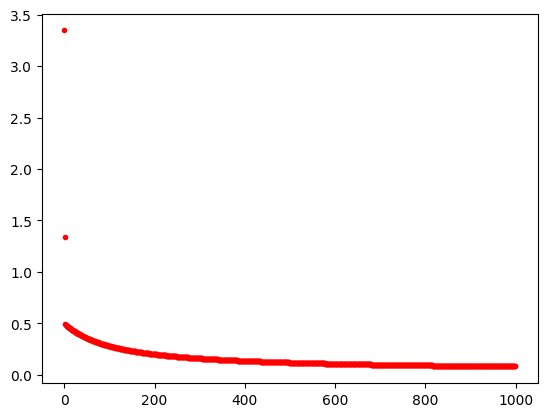

In [29]:
plt.plot(J, '.r')
plt.show()

In [34]:
J[-10:]

array([[0.08243415],
       [0.08238999],
       [0.0823459 ],
       [0.0823019 ],
       [0.08225797],
       [0.08221411],
       [0.08217033],
       [0.08212662],
       [0.08208299],
       [0.08203943]])

In [39]:
x1New, x2New = np.meshgrid(
   np.linspace(4,8,100).reshape(-1,1),
   np.linspace(2,6,100).reshape(-1,1) 
)
XNew = np.column_stack([np.ones_like(x1New.ravel()), x1New.ravel(), x2New.ravel()])
yH = sigmoid(XNew@thetaH).reshape(x1New.shape)
yH

array([[2.38532036e-01, 2.16820148e-01, 1.96574360e-01, ...,
        1.95510602e-06, 1.72787955e-06, 1.52706176e-06],
       [2.75169857e-01, 2.51223331e-01, 2.28703202e-01, ...,
        2.36940700e-06, 2.09402971e-06, 1.85065727e-06],
       [3.15106415e-01, 2.89070482e-01, 2.64355452e-01, ...,
        2.87150108e-06, 2.53776955e-06, 2.24282486e-06],
       ...,
       [9.99999974e-01, 9.99999971e-01, 9.99999967e-01, ...,
        9.95921419e-01, 9.95387535e-01, 9.94784131e-01],
       [9.99999979e-01, 9.99999976e-01, 9.99999973e-01, ...,
        9.96632176e-01, 9.96190974e-01, 9.95692221e-01],
       [9.99999983e-01, 9.99999980e-01, 9.99999978e-01, ...,
        9.97219419e-01, 9.96854905e-01, 9.96442776e-01]])

In [40]:
thetaH

array([[ 1.55698713],
       [-3.05785477],
       [ 4.75684373]])

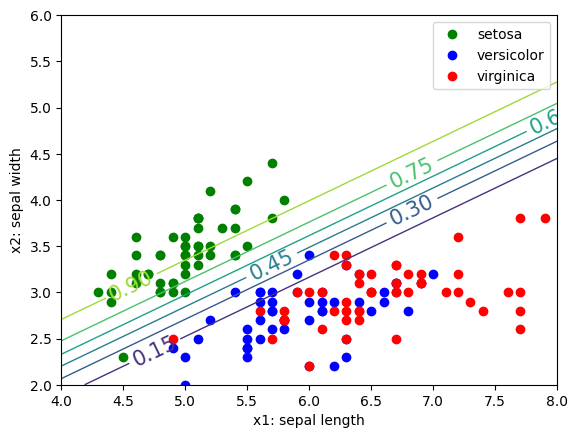

In [43]:
plt.plot(x1[y==0],x2[y==0],'og', label='setosa')
plt.plot(x1[y==1],x2[y==1],'ob', label='versicolor')
plt.plot(x1[y==2],x2[y==2],'or', label='virginica')
contour = plt.contour(x1New, x2New,yH, linewidths=1)
plt.clabel(contour,inline=1,fontsize=15)
plt.xlabel('x1: sepal length')
plt.ylabel('x2: sepal width')
plt.legend()
plt.show()

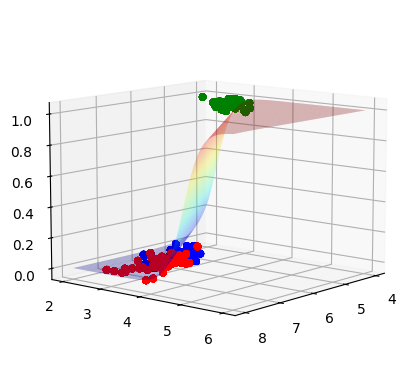

In [49]:
fig, ax =plt.subplots(subplot_kw={"projection": "3d"})
surf = ax.plot_surface(x1New,x2New,yH, cmap='jet',alpha=0.3)
ax.scatter(x1[y==0], x2[y==0], Yt[y==0], 'o', color='green')
ax.scatter(x1[y==1], x2[y==1], Yt[y==1], 'o', color='blue')
ax.scatter(x1[y==2], x2[y==2], Yt[y==2], 'o', color='red')
ax.view_init(10, 40)
plt.show()

# Challenge class

In [50]:
x1 = df['sl'].to_numpy()
x2 = df['pw'].to_numpy()
y = df['target'].to_numpy()

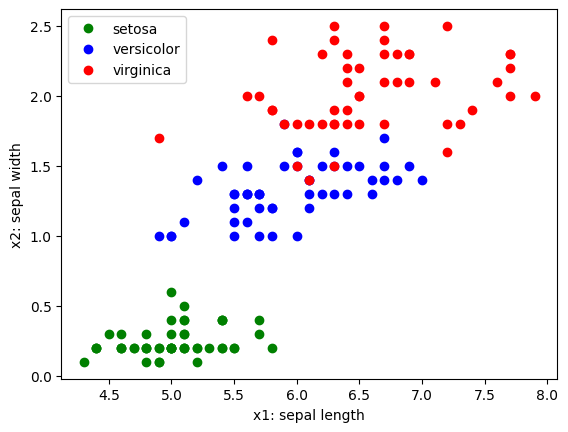

In [51]:
plt.plot(x1[y==0],x2[y==0],'og', label='setosa')
plt.plot(x1[y==1],x2[y==1],'ob', label='versicolor')
plt.plot(x1[y==2],x2[y==2],'or', label='virginica')
plt.xlabel('x1: sepal length')
plt.ylabel('x2: sepal width')
plt.legend()
plt.show()

In [52]:
X = np.column_stack([np.ones_like(x1), x1, x2])
Y = df['target'].to_numpy().reshape(-1,1)
Yt = (Y==1).astype(float) # For Classifying Setosa

In [54]:
# Hyperparameters
eta = 0.1
m = len(x1)
epoch = 1000
thetaH = np.zeros((3,1))
print(thetaH)
J = np.zeros((epoch,1)) #MSE
for i in range(epoch):
    z = X@thetaH
    p = sigmoid(z)
    J[i] = LogLoss(Yt,p)
    nabla = (X.T@(p-Yt))/m
    thetaH = thetaH-eta*nabla

[[0.]
 [0.]
 [0.]]


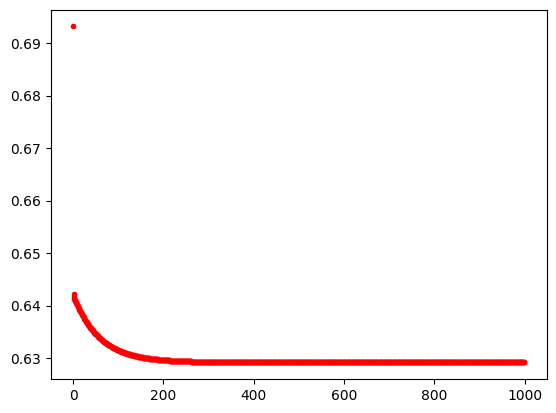

In [55]:
plt.plot(J, '.r')
plt.show()

In [56]:
x1New, x2New = np.meshgrid(
   np.linspace(4,8,100).reshape(-1,1),
   np.linspace(0,2,100).reshape(-1,1) 
)
XNew = np.column_stack([np.ones_like(x1New.ravel()), x1New.ravel(), x2New.ravel()])
yH = sigmoid(XNew@thetaH).reshape(x1New.shape)
yH

array([[0.2792812 , 0.27774204, 0.27620812, ..., 0.15564189, 0.15463793,
        0.15363927],
       [0.28130471, 0.27975873, 0.27821796, ..., 0.15696468, 0.15595376,
        0.15494816],
       [0.28333711, 0.28178434, 0.28023676, ..., 0.15829661, 0.15727871,
        0.15626614],
       ...,
       [0.50624068, 0.50432598, 0.50241115, ..., 0.32782805, 0.32614242,
        0.32446127],
       [0.50874783, 0.50683338, 0.50491872, ..., 0.33004222, 0.32835077,
        0.32666375],
       [0.51125454, 0.50934043, 0.50742605, ..., 0.33226396, 0.33056674,
        0.32887391]])

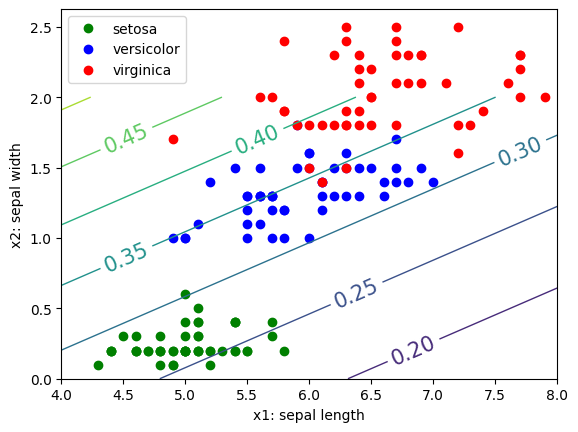

In [57]:
plt.plot(x1[y==0],x2[y==0],'og', label='setosa')
plt.plot(x1[y==1],x2[y==1],'ob', label='versicolor')
plt.plot(x1[y==2],x2[y==2],'or', label='virginica')
contour = plt.contour(x1New, x2New,yH, linewidths=1)
plt.clabel(contour,inline=1,fontsize=15)
plt.xlabel('x1: sepal length')
plt.ylabel('x2: sepal width')
plt.legend()
plt.show()

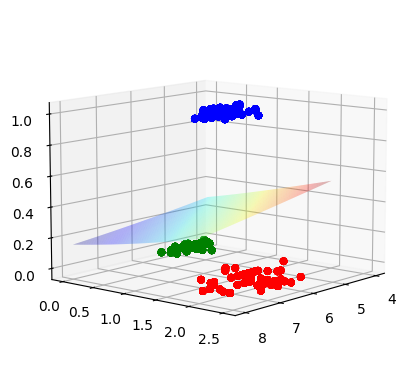

In [58]:
fig, ax =plt.subplots(subplot_kw={"projection": "3d"})
surf = ax.plot_surface(x1New,x2New,yH, cmap='jet',alpha=0.3)
ax.scatter(x1[y==0], x2[y==0], Yt[y==0], 'o', color='green')
ax.scatter(x1[y==1], x2[y==1], Yt[y==1], 'o', color='blue')
ax.scatter(x1[y==2], x2[y==2], Yt[y==2], 'o', color='red')
ax.view_init(10, 40)
plt.show()

# Multi-parametric multi-class classifier